In [6]:
from google.colab import files
uploaded = files.upload()   # select your .py file

Saving full_hatla2ee2026_dataset.csv to full_hatla2ee2026_dataset.csv


In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from wrangle import wrangle

from sklearn.model_selection import train_test_split, validation_curve, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.dummy import DummyRegressor
from sklearn.base import clone
from sklearn.model_selection import KFold, cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import VotingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

In [7]:
df = wrangle("/content/full_hatla2ee2026_dataset.csv")

raw                                      rows =  22429
drop missing price / year                rows =  19502
km set to NaN (fake zeros)               rows =   2944
drop price > 20,000,000                  rows =  19483
drop km > 430,000                        rows =  19292
drop duplicates                          rows =  19209


In [8]:
df.head()

,brand,km,fuel,transmission,price,car_age,brand_model
0,Kia,122000.0,Gas,Automatic,530000.0,13.0,Kia Rio
1,Chevrolet,2017.0,Gas,Automatic,395000.0,9.0,Chevrolet Aveo
2,Hyundai,260000.0,Diesel,Automatic,410000.0,20.0,Hyundai Matrix
3,Nissan,50000.0,Gas,Automatic,1320000.0,1.0,Nissan Qashqai
4,Daewoo,260000.0,Gas,Manual,255000.0,20.0,Daewoo Lanos 2


# **splitting the data vertically and horizontally **

In [9]:
target="price"
y=df[target]
X=df.drop(columns=target)

In [10]:
X_train, X_t_v, y_train, y_t_v= train_test_split(
    X, y, test_size=0.3, random_state=42)

In [11]:
X_test , X_val , y_test ,y_val = train_test_split(
    X_t_v, y_t_v, test_size=0.5, random_state=42)

## **encoding PipeLine& report function**

In [12]:
num = ["km", "car_age"]
low = ["fuel", "transmission"]
high = ["brand", "brand_model"]

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                      ("sc", StandardScaler())]), num),
    ("low", OneHotEncoder(handle_unknown="ignore"), low),
    ("high", Pipeline([("te", TargetEncoder(smooth="auto", random_state=42)),
                       ("sc", StandardScaler())]), high),
])

In [13]:
def report(name, model):
    p = model.predict(X_val)
    return {"model": name,
            "MAE": mean_absolute_error(y_val, p),
            "RMSE": root_mean_squared_error(y_val, p),
            "R2": r2_score(y_val, p),
            "MedAPE %": 100 * np.median(np.abs(y_val - p) / y_val)}

# **model and base Line**

In [14]:
knn = TransformedTargetRegressor(
    regressor=Pipeline([("pre", pre),
                        ("knn", KNeighborsRegressor(n_neighbors=10, weights="distance"))]),
    func=np.log1p, inverse_func=np.expm1)

In [15]:
dummy = DummyRegressor(strategy="median").fit(X_train, y_train)

In [16]:
dummy_2 = DummyRegressor(strategy="mean").fit(X_train, y_train)

In [17]:
knn_base = TransformedTargetRegressor(
    regressor=Pipeline([("pre", pre), ("knn", KNeighborsRegressor())]),
    func=np.log1p, inverse_func=np.expm1).fit(X_train, y_train)

In [18]:
pd.DataFrame([report("mean" , dummy_2 ) ,report("median", dummy), report("KNN default", knn_base)]).round(2)

,model,MAE,RMSE,R2,MedAPE %
0,mean,970737.96,1598276.52,-0.00,81.65
1,median,838970.30,1682672.79,-0.11,57.06
2,KNN default,256275.52,668846.24,0.82,12.48


# **hyperparameters and tuning**

In [19]:
ks = [3, 5, 10, 15, 20, 30, 50, 80]
tr, cv = validation_curve(knn_base, X_train, y_train,
                          param_name="regressor__knn__n_neighbors", param_range=ks,
                          cv=5, scoring="neg_mean_absolute_error", n_jobs=-1)

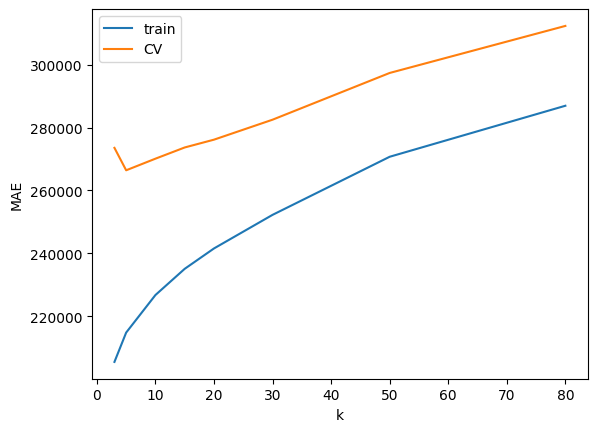

In [20]:
plt.plot(ks, -tr.mean(axis=1), label="train")
plt.plot(ks, -cv.mean(axis=1), label="CV")
plt.xlabel("k"); plt.ylabel("MAE"); plt.legend(); plt.show()

In [21]:
ks[(-cv.mean(axis=1)).argmin()]

5

In [22]:
grid = GridSearchCV(knn_base,
    {"regressor__knn__n_neighbors": [5, 10, 15, 20, 30],
     "regressor__knn__weights": ["uniform", "distance"],
     "regressor__knn__p": [1, 2]},
    cv=5, scoring="neg_mean_absolute_error", n_jobs=-1).fit(X_train, y_train)

In [23]:
grid.best_params_, -grid.best_score_

({'regressor__knn__n_neighbors': 10,
  'regressor__knn__p': 1,
  'regressor__knn__weights': 'distance'},
 np.float64(257883.96090215462))

In [24]:
pd.DataFrame(grid.cv_results_).sort_values("rank_test_score")[["params", "mean_test_score"]].head(10)

,params,mean_test_score
5,"{'regressor__knn__n_neighbors': 10, 'regressor...",-257883.960902
9,"{'regressor__knn__n_neighbors': 15, 'regressor...",-259712.955883
7,"{'regressor__knn__n_neighbors': 10, 'regressor...",-259889.785778
13,"{'regressor__knn__n_neighbors': 20, 'regressor...",-260605.590996
11,"{'regressor__knn__n_neighbors': 15, 'regressor...",-261086.762178
15,"{'regressor__knn__n_neighbors': 20, 'regressor...",-262022.016257
3,"{'regressor__knn__n_neighbors': 5, 'regressor_...",-262893.849586
17,"{'regressor__knn__n_neighbors': 30, 'regressor...",-263185.541578
1,"{'regressor__knn__n_neighbors': 5, 'regressor_...",-263201.403793
19,"{'regressor__knn__n_neighbors': 30, 'regressor...",-265094.260301


In [25]:
pd.DataFrame([report("median", dummy), report("KNN default", knn_base),
              report("KNN tuned", grid.best_estimator_)]).round(2)

,model,MAE,RMSE,R2,MedAPE %
0,median,838970.30,1682672.79,-0.11,57.06
1,KNN default,256275.52,668846.24,0.82,12.48
2,KNN tuned,237858.48,621691.91,0.85,11.62


# **ensampled model**

In [26]:
knn_pipe = Pipeline([("pre", pre), ("knn", KNeighborsRegressor())])

def member(k, w, p):
    return clone(knn_pipe).set_params(knn__n_neighbors=k, knn__weights=w, knn__p=p)

In [46]:
members = [("m1", member(10, "distance", 1)),
           ("m2", member(15, "distance", 1)),
           ("m3", member(10, "distance", 2)),
           ("m4", member(20, "distance", 1)),
           ("m5", member(15, "distance", 2)),
           ("m6", member(20, "distance", 2)),
           ("m7", member(5, "distance", 2)),
           ("m8", member(30, "distance", 1))
           ]

In [47]:
ens = TransformedTargetRegressor(
    regressor=VotingRegressor(members, n_jobs=-1),
    func=np.log1p, inverse_func=np.expm1).fit(X_train, y_train)

In [48]:
pd.DataFrame([report("median", dummy), report("KNN default", knn_base),
              report("KNN tuned", grid.best_estimator_), report("Ensemble", ens)]).round(2)

,model,MAE,RMSE,R2,MedAPE %
0,median,838970.30,1682672.79,-0.11,57.06
1,KNN default,256275.52,668846.24,0.82,12.48
2,KNN tuned,237858.48,621691.91,0.85,11.62
3,Ensemble,237496.03,617783.20,0.85,11.93


# **cross validation tuned model and ensampled one with the training data **

In [50]:
cv5 = KFold(5, shuffle=True, random_state=42)
a = -cross_val_score(grid.best_estimator_, X_train, y_train, cv=cv5, scoring="neg_mean_absolute_error")
b = -cross_val_score(ens, X_train, y_train, cv=cv5, scoring="neg_mean_absolute_error")
pd.DataFrame({"tuned": a, "ensemble": b})

,tuned,ensemble
0,253288.373672,251969.688532
1,240619.326907,240771.793548
2,274804.695039,275296.873988
3,250564.987586,251857.792659
4,269561.837072,262763.764004


# Used-Car Price Prediction: KNN (v0.5)

**Status:** paused 2026-11-25. Test set not used yet.
**Current model:** tuned single KNN.

## Data (`wrangle.py`)
- Dropped `description` and rows with no `price`
- `km`, `price` to numbers; added `car_age` and `brand_model`
- `km == 0` on cars aged 2+ set to NaN (~25% of rows)
- Fixed caps: `price <= 20M`, `km <= 430k`; duplicates dropped

## Pipeline
- `km`, `car_age`: median impute + missing flag, then scale
- `fuel`, `transmission`: one-hot
- `brand`, `brand_model`: target encode, then scale
- Target: `log1p(price)`, predictions back in EGP

## Results
- Baselines: median predictor, default KNN
- Tuned: `k` sweep, then grid over `k`, `weights`, `p`
- Best params: *paste here* | Val metrics: *paste report table here*
- Ensemble of 4 KNNs vs tuned KNN (5-fold CV): MAE 256,532 vs 257,768. Gain 0.5%, won 2 of 5 folds. **No reliable gain, so tuned KNN kept.**

## Open issues
- MAE ~250k EGP: data quality is probably the limit
- Placeholder prices (20,000 EGP luxury cars) and typo `km` remain

## Next
1. Inspect 20 worst validation errors
2. Fix in `wrangle`, retune
3. Freeze, test once, compare with Linear Regression

In [51]:
def test_report(model):
    p = model.predict(X_test)
    return {"MAE": mean_absolute_error(y_test, p), "RMSE": root_mean_squared_error(y_test, p),
            "R2": r2_score(y_test, p), "MedAPE %": 100 * np.median(np.abs(y_test - p) / y_test)}

pd.DataFrame({"median": test_report(dummy), "KNN tuned": test_report(grid.best_estimator_)}).round(2)

,median,KNN tuned
MAE,816978.26,255373.20
RMSE,1656182.82,758924.18
R2,-0.10,0.77
MedAPE %,56.25,11.67


## How to improve the model (future work)

Test set used once at v0.5. Re-score on new test only as a new version (v1.0), and say so.

### 1. Data quality (biggest gain)
- Inspect the 20 worst validation errors, then fix patterns in `wrangle`
- Add a price floor for placeholders (luxury cars listed at exactly 20,000 EGP)
- Add rules for typo `km` (for example, `km` equal to the model year)
- Revisit the price cap (20M) and `km` cap (430k) after looking at the rows
- Check `brand` split on first word only ("Land", "Aston", "Rolls")

### 2. Missing `km` (~25%)
- Compare median fill vs `IterativeImputer` (uses `car_age`, brand)
- Report error separately for real vs imputed `km`

### 3. Features
- Add `car_age²` and `log(km)`
- Add group features: median price per `brand`, mean `km` per `car_age`
- Try `km` per year of age
- Group rare `brand_model` values into "Other"

### 4. Encoding and scaling
- Compare target vs frequency encoding for `brand_model`
- Test dropping `brand` (does `brand_model` alone do as well?)
- Test feature weights (multiply scaled columns) since KNN weighs all columns equally
- Check if one-hot columns need scaling

### 5. Models
- Ensemble with different **features or encodings** per member (not just `k`)
- Stack KNN with Ridge or a tree model (Random Forest, XGBoost, CatBoost)
- Tree models skip scaling and handle `brand_model` natively (CatBoost)

### 6. Evaluation
- Error by price band (cheap, mid, expensive)
- Learning curve: does more data still help?
- Permutation importance for the KNN
- Use median APE next to MAE (MAE is dominated by expensive cars)
- Keep a fixed validation table across versions (v0.5, v1.0, ...)

### 7. Data limits (cannot fix with modeling)
- No trim, condition, city, or listing date in the data
- Prices change over time (inflation), and a random split ignores that
- Realistic ceiling: errors around 20-30% of price